# Ex 4 — Descriptive Statistics and Correlation

**Dataset:** fanspeed.csv  
**Reg No:** URK24CS1021

In [1]:
print("URK24CS1021")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)

df = pd.read_csv("fanspeed.csv")
df.head()

URK24CS1021


,Temperature,Observed Fan Speed
0,5.000000,22.483571
1,5.303030,19.914739
2,5.606061,24.450564
3,5.909091,29.433331
4,6.212121,21.253476


### Where does the data sit? — mean, median, mode

In [2]:
print("URK24CS1021")

pd.DataFrame({"mean": df.mean(), "median": df.median()})

URK24CS1021


,mean,median
Temperature,20.000000,20.000000
Observed Fan Speed,66.568646,69.669067


In [3]:
print("URK24CS1021")

# every reading is unique, so every value ties as a mode
len(df["Temperature"].mode()), len(df["Observed Fan Speed"].mode())

URK24CS1021


(100, 100)

In [4]:
print("URK24CS1021")

# no categorical column in the file, so bin temperature into one
df["Temp_Band"] = pd.cut(df["Temperature"], bins=[5, 15, 25, 35],
                         labels=["Low", "Mid", "High"], include_lowest=True)
df["Temp_Band"].mode()

URK24CS1021


0    Low
Name: Temp_Band, dtype: category
Categories (3, object): ['Low' < 'Mid' < 'High']

### How spread out is it? — variance, std, range, IQR

In [5]:
print("URK24CS1021")

nums = df.select_dtypes(include="number")
pd.DataFrame({"variance": nums.var(), "std": nums.std(),
              "range": nums.max() - nums.min()})

URK24CS1021


,variance,std,range
Temperature,77.288032,8.791361,30.000000
Observed Fan Speed,903.929394,30.065419,96.174708


In [6]:
print("URK24CS1021")

q1, q3 = nums.quantile(0.25), nums.quantile(0.75)
iqr = q3 - q1
pd.DataFrame({"IQR": iqr, "lower fence": q1 - 1.5 * iqr,
              "upper fence": q3 + 1.5 * iqr})

URK24CS1021


,IQR,lower fence,upper fence
Temperature,15.000000,-10.000000,50.000000
Observed Fan Speed,53.865949,-40.904614,174.559182


In [7]:
print("URK24CS1021")

# how many rows fall outside the 1.5xIQR fences
col = "Observed Fan Speed"
low, high = q1[col] - 1.5 * iqr[col], q3[col] + 1.5 * iqr[col]
((nums[col] < low) | (nums[col] > high)).sum()

URK24CS1021


np.int64(0)

### Do the two columns move together? — correlation

In [8]:
print("URK24CS1021")

corr = nums.corr()
corr

URK24CS1021


,Temperature,Observed Fan Speed
Temperature,1.000000,0.985198
Observed Fan Speed,0.985198,1.000000


In [9]:
print("URK24CS1021")

pearson = df["Temperature"].corr(df["Observed Fan Speed"], method="pearson")
spearman = df["Temperature"].corr(df["Observed Fan Speed"], method="spearman")
round(pearson, 4), round(spearman, 4)

URK24CS1021


(np.float64(0.9852), np.float64(0.9841))

URK24CS1021


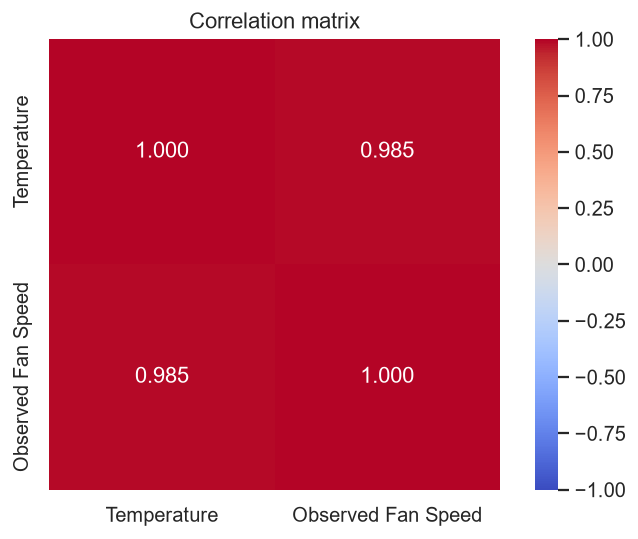

In [10]:
print("URK24CS1021")

sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix")
plt.show()

### Seeing it — regression line, box plot, histogram, pair plot

URK24CS1021


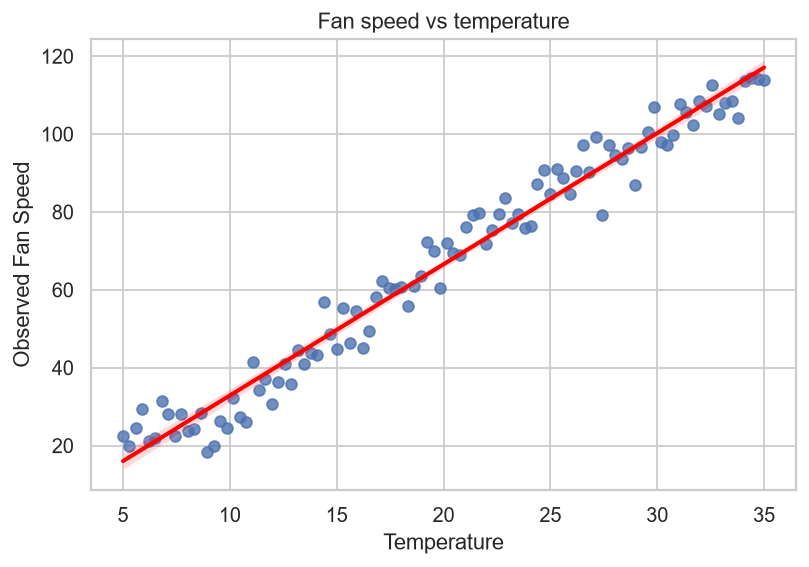

In [11]:
print("URK24CS1021")

sns.regplot(data=df, x="Temperature", y="Observed Fan Speed", line_kws={"color": "red"})
plt.title("Fan speed vs temperature")
plt.show()

URK24CS1021


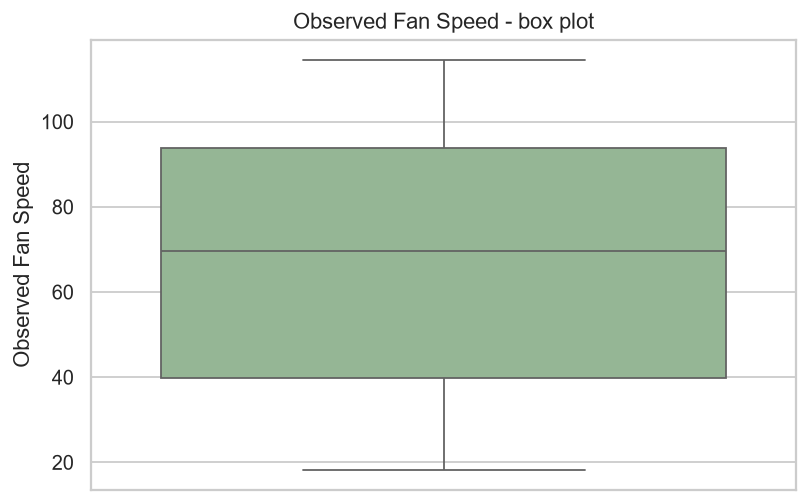

In [12]:
print("URK24CS1021")

sns.boxplot(y=df["Observed Fan Speed"], color="#8FBC8F")
plt.title("Observed Fan Speed - box plot")
plt.show()

In [13]:
print("URK24CS1021")

df["Observed Fan Speed"].skew()

URK24CS1021


np.float64(-0.06091615438100633)

URK24CS1021


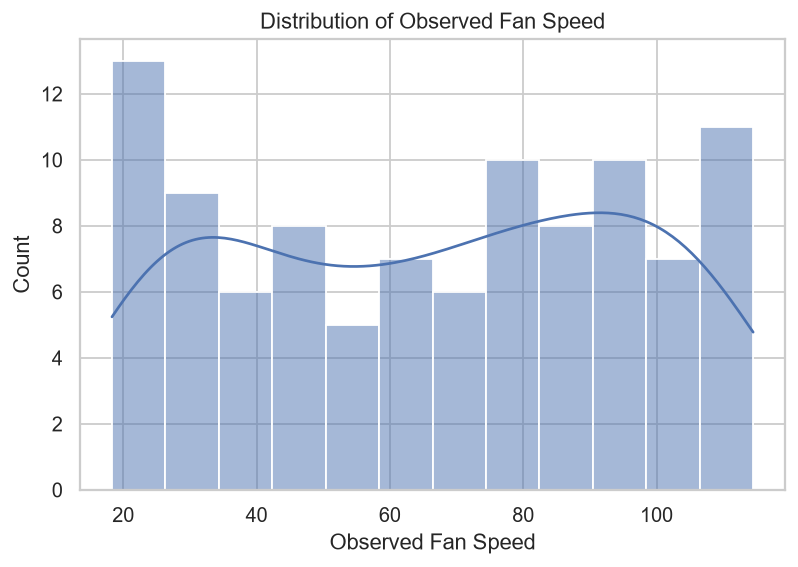

In [14]:
print("URK24CS1021")

sns.histplot(df["Observed Fan Speed"], bins=12, kde=True)
plt.title("Distribution of Observed Fan Speed")
plt.show()

URK24CS1021


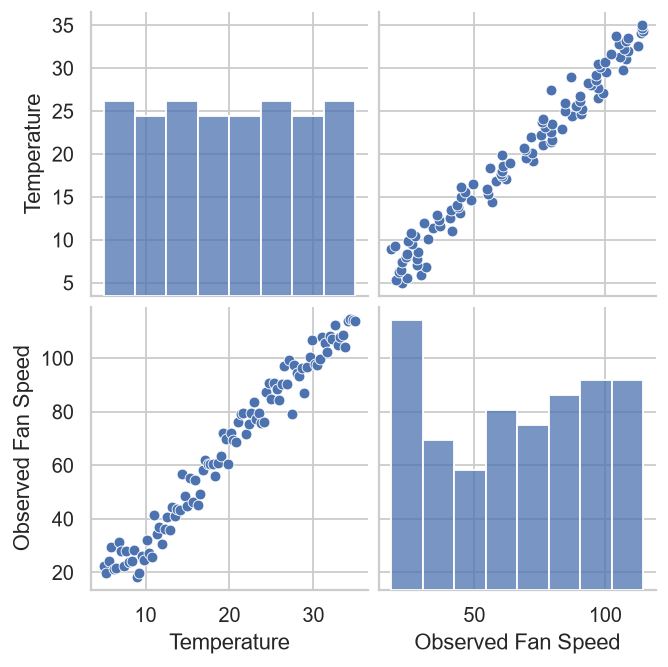

In [15]:
print("URK24CS1021")

sns.pairplot(nums, diag_kind="hist", height=2.6)
plt.show()